In [ ]:
# Activity 1: Dataset Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# Load Iris dataset
iris = load_iris(as_frame=True)
df = iris.frame.copy()

# Rename target column
df.rename(columns={"target": "species_code"}, inplace=True)

# Convert species codes into names
df["species"] = df["species_code"].map(
    dict(enumerate(iris.target_names))
)
df.drop(columns=["species_code"], inplace=True)

print("First five rows:")
print(df.head())

print("\nLast five rows:")
print(df.tail())

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Last five rows:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149           

In [2]:
# Create a working copy for demonstration
df.loc[0, "sepal length (cm)"] = np.nan
df.loc[1, "species"] = np.nan

# Add a duplicate row for demonstration
df = pd.concat([df, df.iloc[[2]]], ignore_index=True)

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
print(df.describe())

Missing values:
sepal length (cm)    1
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              1
dtype: int64

Duplicate rows: 2

Summary statistics:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        151.000000         151.000000   
mean            5.840667          3.058278           3.741722   
std             0.831114          0.434566           1.770738   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.550000   
50%             5.800000          3.000000           4.300000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        151.000000  
mean           1.192715  
std            0.764033  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.50000

In [3]:
# Fill numerical missing values using the median
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values using the mode
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Remove duplicate records
df = df.drop_duplicates().copy()

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicates after cleaning:", df.duplicated().sum())
print("Final shape after cleaning:", df.shape)

Missing values after cleaning:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicates after cleaning: 0
Final shape after cleaning: (149, 5)


In [4]:
# Fill numerical missing values using the median
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values using the mode
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Remove duplicate records
df = df.drop_duplicates().copy()

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicates after cleaning:", df.duplicated().sum())
print("Final shape after cleaning:", df.shape)

Missing values after cleaning:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicates after cleaning: 0
Final shape after cleaning: (149, 5)


species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


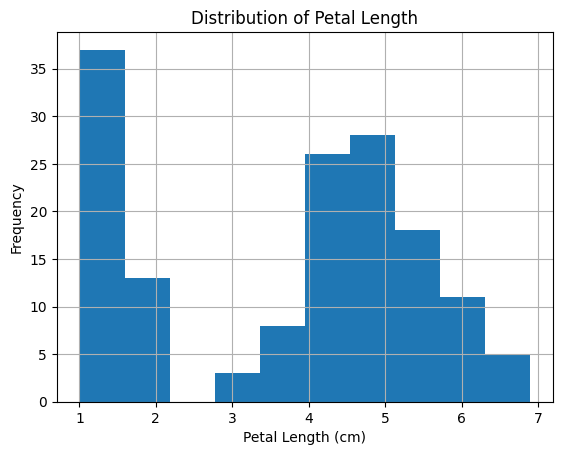

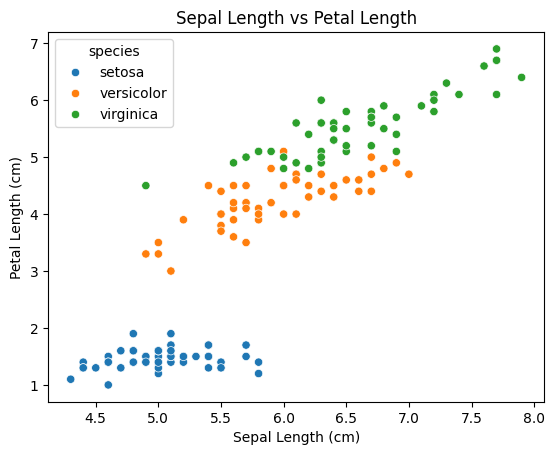

In [5]:
# Frequency count of each species
print(df["species"].value_counts())

# Histogram
df["petal length (cm)"].hist()
plt.title("Distribution of Petal Length")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Frequency")
plt.show()

# Scatter plot
sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="petal length (cm)",
    hue="species"
)
plt.title("Sepal Length vs Petal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.show()

In [6]:
# One-hot encoding of species
encoded_df = pd.get_dummies(
    df, columns=["species"], dtype=int
)

# Standardize numerical features
feature_cols = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)",
    "petal width (cm)"
]

scaler = StandardScaler()
encoded_df[feature_cols] = scaler.fit_transform(
    encoded_df[feature_cols]
)

print(encoded_df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0          -0.058515          1.012401          -1.333255         -1.308624   
1          -1.148356         -0.137353          -1.333255         -1.308624   
2          -1.390542          0.322549          -1.390014         -1.308624   
3          -1.511636          0.092598          -1.276496         -1.308624   
4          -1.027262          1.242352          -1.333255         -1.308624   

   species_setosa  species_versicolor  species_virginica  
0               1                   0                  0  
1               1                   0                  0  
2               1                   0                  0  
3               1                   0                  0  
4               1                   0                  0  


In [7]:
encoded_df.to_csv(
    "prepared_iris_dataset.csv", index=False
)

print("Prepared dataset saved successfully.")
print("Final dataset shape:", encoded_df.shape)
print("Remaining missing values:",
      encoded_df.isnull().sum().sum())
print("Remaining duplicates:",
      encoded_df.duplicated().sum())

Prepared dataset saved successfully.
Final dataset shape: (149, 7)
Remaining missing values: 0
Remaining duplicates: 0
